# 07 — Candidate regulators (evidence-based ranking)

Replaces the template's `07_novel_drivers`, which ranks every gene in a disease-relevant regulon by how many MSigDB hallmark sets it belongs to, rewarding genes that sit in many hallmark sets in any cancer (GADD45B tops both GBM and KIRC). This notebook ranks **transcription factors**, the control points MINER actually proposes, using evidence specific to this cancer.

`{prefix}` = `CANCER.lower()`, `{val}` = validation cohort name in lower case. **Only the config lines in the first code cell need editing for a new cancer.**

## Evidence lines

| # | Evidence | Rule | Source |
|---|---|---|---|
| E1 | TF's regulons are enriched among disease-relevant regulons | hypergeometric test, FDR ≤ 0.05, at least 3 such regulons | 04 |
| E2 | Its survival-associated regulons point the same way | ≥ 3 survival-significant regulons, ≥ 80% all risk (HR > 1) or all protective (HR < 1) | 04 |
| E3 | Downstream of a driver mutation of this cancer | ≥ 1 filtered causal flow: driver mutation → TF → a disease-relevant regulon. Driver = IntOGen driver call for this cancer; tier **known** (also in the Cancer Gene Census) or **candidate** (not in it), from `driver_tiers.py` | 02 |
| E4 | TF's **activity** predicts survival, in TCGA and the independent cohort together | TF activity = signed mean of its regulons' scores (mean z-score of their genes; sign from the TF–regulon correlation in TCGA). Cox score test stratified by cohort (independent cohort on disease-specific survival if recorded), adjusted for stromal / immune scores; FDR ≤ 0.05. The Cox on the TF's own mRNA is kept as an annotation (`own_*`) | 01, 03, 04 |
| E5 | Master regulator of at least one transcriptional state | present in `master_regulators_per_state.csv` | 06 |

**Ranking.** The TFs are ranked separately on each line (E1 enrichment p-value, E2 binomial p-value of risk vs protective regulons, E3 number of driver flows, E4 activity Cox p-value, E5 number of states) and the five rankings are combined with the Robust Rank Aggregation score (Kolde et al. 2012, `rra_rho`). Its p-value (`rra_p`, `rra_fdr`) comes from a permutation test, not from the RRA formula: the regulon → TF assignment is shuffled 1,000 times (each TF keeps its number of regulons), E1–E4 are recomputed and the observed score is compared with all shuffled scores. This keeps the dependence between the lines (E1, E3 and E5 all grow with the number of regulons), which the analytic RRA p-value ignores. E5 stays with its TF in the shuffles. The rules in the table are kept only as descriptive flags (`evidence_score`, 0–5); they do not set the rank.

**Tumour purity.** If `SI_geneset.gmt` (the ESTIMATE stromal and immune signatures, Yoshihara et al. 2013) is in `base_dir`, a stromal and an immune score are computed per tumour by ssGSEA (Barbie et al. 2009) and used as covariates in E4, so a TF is not credited for tracking the amount of non-tumour tissue. Without the file E4 is unadjusted and the notebook says so. Extra output: `stromal_immune_scores.csv`.

TFs that are not expressed (below `MIN_TPM` in more than `1 − MIN_FRAC` of tumours) are kept in the table but excluded from the ranking. Prior knowledge (Open Targets) is added at the end as an annotation; it does not affect the rank.

## Inputs

| File | From | Used for |
|---|---|---|
| `{prefix}_output/regulonDf.csv` | 02 | which TF controls which regulon |
| `{prefix}_output/regulon_cox_results.csv` | 04 | HR and p-value per regulon |
| `{prefix}_output/final_disease_relevant_regulons.csv` | 04 | disease-relevant set (no header) |
| `{prefix}_output/{val}_coexp_validated_regulons.csv` | 04 | regulons replicated in the independent cohort (no header) |
| `{prefix}_output/filteredCausalResults.csv` | 02 | mutation → TF → regulon flows |
| `{prefix}_output/master_regulators_per_state.csv`, `tf_network_degrees.csv` | 06 | master regulators, out/in ratio (optional) |
| `{prefix}_output/clinical_data.csv` | 03 | survival for the TF-level Cox test |
| `{prefix}_log2tpm.csv` | 01 | TF expression |
| `{prefix}_data/driver_genes.csv`, `open_targets_associations.csv` | `driver_tiers.py` (fetched once, then cached) | driver tiers for E3; Open Targets scores for the annotation |

## Outputs (in `{prefix}_output/`)

| File | Format |
|---|---|
| `candidate_regulators.csv` | one row per TF: regulon counts, enrichment p / FDR, direction, upstream driver mutations (all, and split into `upstream_known` / `upstream_candidate`), expression, own Cox HR / FDR, master-regulator states, E1–E5 flags, `evidence_score` (0–5), Open Targets score and status |
| `candidate_regulators_top20.png` | top 20 ranked TFs |

## What this does and does not show

These are **candidate regulators**, not drivers. "Driver" means a gene whose mutations are selected for in tumours, which only mutation-based methods can establish. Everything here is association in patient data. Functional evidence (for example DepMap CRISPR dependency in cell lines of this cancer) and tumour-vs-normal expression are the natural next columns to add.

In [1]:
# Necessary imports
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import miner.miner as miner
from scipy.stats import hypergeom, beta, binomtest
from lifelines import CoxPHFitter

warnings.filterwarnings("ignore")

# CANCER CONFIGURATION: the only lines to edit for a new cancer
CANCER     = "UCEC"
base_dir   = r"causal_inf_new"
prefix     = CANCER.lower()

# this cancer's own folder: holds <prefix>_data, <prefix>_notebooks and <prefix>_output
cancer_dir = os.path.join(base_dir, prefix)
data_dir   = os.path.join(cancer_dir, f"{prefix}_data")
output_dir = os.path.join(cancer_dir, f"{prefix}_output")

# Independent cohort used in 04 (same dictionary as 04 / 05)
VALIDATION_COHORTS = {"BRCA": ("METABRIC", "brca_metabric"), "KIRC": ("EMTAB1980", "kirc_emtab1980"),
                      "LUAD": ("GSE72094", "luad_gse72094"),
                      "UCEC": ("CPTAC", "ucec_cptac_2020")}
val = VALIDATION_COHORTS[CANCER][0].lower()

# Driver gene tiers: published driver calls per cancer (module driver_tiers.py in base_dir, shared by 02, 06 and 07)
import sys
if base_dir not in sys.path:
    sys.path.insert(0, base_dir)
from driver_tiers import get_driver_tiers

# Driver genes of this cancer for evidence line E3: same table as 02 and 06
# both tiers need an IntOGen driver call for this cancer: "known" = also in the Cancer Gene Census, "candidate" = not in it
driver_table = get_driver_tiers(CANCER, data_dir)
tier_of = dict(zip(driver_table["Gene"], driver_table["Tier"]))

# A TF must reach MIN_TPM in at least MIN_FRAC of tumours to be ranked
MIN_TPM  = 1.0
MIN_FRAC = 0.20

assert os.path.isdir(output_dir), f"missing output folder: {output_dir}"
miner_dir  = os.path.dirname(miner.__file__)
idmap_path = os.path.join(miner_dir, "data", "identifier_mappings.txt")
print(f"Cancer: {CANCER} | outputs: {output_dir} | validation cohort: {val}")

Open Targets search hits for 'endometrial carcinoma': [('MONDO_0002447', 'endometrial carcinoma'), ('MONDO_0011962', 'endometrial cancer'), ('MONDO_0006196', 'endometrial serous adenocarcinoma'), ('MONDO_0000553', 'uterine corpus endometrial carcinoma'), ('MONDO_0000931', 'endometrial disorder')]
Using the provisional built-in list for UCEC (22 genes). This is NOT a citable source; rerun with internet access
Cancer: UCEC | outputs: causal_inf_new\ucec\ucec_output | validation cohort: cptac


In [2]:
# Load the pipeline outputs

def bh_fdr(pvals):

    '''

    Benjamini-Hochberg FDR correction. NaN p-values are ignored and returned as NaN.

    Args: pvals (Series). Raw p-values, any index

    Returns: Series, same index. q-values

    '''

    p = pvals.dropna().sort_values()
    q = p * len(p) / np.arange(1, len(p) + 1)
    q = q[::-1].cummin()[::-1].clip(upper=1)
    return q.reindex(pvals.index)

def read_id_list(name):

    '''

    Reads a regulon list saved without a header (one regulon ID per line).

    Args: name (str). File name inside output_dir

    Returns: set of int regulon IDs

    '''

    return set(pd.read_csv(os.path.join(output_dir, name), header=None)[0].astype(int))

# Ensembl -> gene symbol
idmap = pd.read_csv(idmap_path, sep="\t", header=0)
names = idmap[idmap["Source"] == "Gene Name"]
ensembl_to_symbol = dict(zip(names["Preferred_Name"], names["Name"]))

# One row per (regulon, TF, gene); each regulon has exactly one TF
regulon_df = pd.read_csv(os.path.join(output_dir, "regulonDf.csv"), index_col=0)

# HR and p-value per regulon (index = regulon ID)
cox = pd.read_csv(os.path.join(output_dir, "regulon_cox_results.csv"), index_col=0)

# Disease-relevant regulons (final set of 04) and regulons replicated in the independent cohort
final_regulons     = read_id_list("final_disease_relevant_regulons.csv")
validated_regulons = read_id_list(f"{val}_coexp_validated_regulons.csv")

# Filtered causal flows: mutation -> TF (symbol) -> regulon ("R-123")
# Only the three columns used here are read (in heavily mutated cancers this file has millions of rows)
causal = pd.read_csv(os.path.join(output_dir, "filteredCausalResults.csv"),
                     usecols=["Mutation", "Regulator", "Regulon"], dtype="category")

# Keep flows from this cancer's driver genes only (all flows if there is no list), then go back to plain text columns
if tier_of:
    causal = causal[causal["Mutation"].isin(tier_of.keys())]
causal = causal.astype(str)
causal["Regulon_ID"] = causal["Regulon"].astype(str).str.replace("R-", "", regex=False).astype(int)

# Survival and expression for the TF-level tests
clinical = pd.read_csv(os.path.join(output_dir, "clinical_data.csv"), index_col=0)
log_tpm  = pd.read_csv(os.path.join(data_dir, f"{prefix}_log2tpm.csv"), index_col=0)

print(f"regulons: {regulon_df['Regulon_ID'].nunique()} | TFs: {regulon_df['Regulator'].nunique()} | "
      f"disease-relevant: {len(final_regulons)} | validated: {len(validated_regulons)} | causal flows: {len(causal)}")

regulons: 7557 | TFs: 611 | disease-relevant: 1208 | validated: 4377 | causal flows: 17098


In [3]:
# Evidence E1 and E2: what each TF's regulons look like

# One row per regulon: its TF (as a symbol), survival statistics and set membership
reg = regulon_df[["Regulon_ID", "Regulator"]].drop_duplicates().set_index("Regulon_ID")
assert reg.index.is_unique, "a regulon is assigned to more than one TF"
reg["TF"] = reg["Regulator"].map(ensembl_to_symbol).fillna(reg["Regulator"])
reg = reg.join(cox[["HR", "p_value"]])
reg["survival_sig"] = reg["p_value"] <= 0.05
reg["risk"]         = reg["survival_sig"] & (reg["HR"] > 1)
reg["protective"]   = reg["survival_sig"] & (reg["HR"] < 1)
reg["validated"]    = reg.index.isin(validated_regulons)
reg["final"]        = reg.index.isin(final_regulons)

# Counts per TF
tf = reg.groupby("TF").agg(
    n_regulons=("TF", "size"),
    n_final=("final", "sum"),
    n_validated=("validated", "sum"),
    n_survival=("survival_sig", "sum"),
    n_risk=("risk", "sum"),
    n_protective=("protective", "sum"),
).astype(int)

# E1: does this TF hold more disease-relevant regulons than expected by chance?
# Hypergeometric test: drawing n_regulons from all regulons, probability of getting >= n_final disease-relevant ones
# Testing against the background rate means a TF is not rewarded just for having many regulons
n_all, n_all_final = len(reg), int(reg["final"].sum())
tf["frac_final"]   = tf["n_final"] / tf["n_regulons"]
tf["enrich_p"]     = hypergeom.sf(tf["n_final"] - 1, n_all, n_all_final, tf["n_regulons"])
tf["enrich_fdr"]   = bh_fdr(tf["enrich_p"])

# E2: do its survival-associated regulons agree in direction?
tf["direction_consistency"] = (tf[["n_risk", "n_protective"]].max(axis=1) / tf["n_survival"]).where(tf["n_survival"] > 0)
tf["direction"] = np.where(tf["n_risk"] > tf["n_protective"], "risk",
                  np.where(tf["n_protective"] > tf["n_risk"], "protective", "mixed"))

print(f"TFs: {len(tf)} | background rate of disease-relevant regulons: {n_all_final / n_all:.1%}")
print(tf.sort_values("enrich_p").head(10)[["n_regulons", "n_final", "frac_final", "enrich_fdr", "direction", "direction_consistency"]])

TFs: 611 | background rate of disease-relevant regulons: 16.0%
        n_regulons  n_final  frac_final  enrich_fdr   direction  \
TF                                                                
ESR1            20       11    0.550000    0.042103  protective   
FOXA2           25       12    0.480000    0.048091  protective   
AR              20       10    0.500000    0.048091  protective   
BACH2            6        5    0.833333    0.048091  protective   
HDX              6        5    0.833333    0.048091        risk   
ELF5            24       11    0.458333    0.048091  protective   
MYOD1           24       11    0.458333    0.048091        risk   
NKX2-8          18        9    0.500000    0.062181  protective   
POU3F3          25       10    0.400000    0.174030  protective   
REST            25       10    0.400000    0.174030        risk   

        direction_consistency  
TF                             
ESR1                 0.666667  
FOXA2                0.666667  
AR  

In [4]:
# Evidence E3: is the TF downstream of a driver mutation of this cancer?

# Driver genes from driver_tiers.py; if there is no list for this cancer every mutation in the causal results counts
drivers = sorted(tier_of) if tier_of else sorted(set(causal["Mutation"]))
if not tier_of:
    print(f"No driver list for {CANCER}: using all {len(drivers)} mutated genes")

def joined(s):

    '''

    Joins the distinct values of a column into one comma-separated string.

    Args: s (Series). Gene symbols

    Returns: str. Sorted unique symbols separated by ", "

    '''

    return ", ".join(sorted(set(s)))

# Only flows that start at a driver AND end in a disease-relevant regulon count
causal["driver"] = causal["Mutation"].isin(drivers)
causal["Tier"]   = causal["Mutation"].map(tier_of).fillna("none")
causal["final"]  = causal["Regulon_ID"].isin(final_regulons)
strong_flows = causal[causal["driver"] & causal["final"]]

tf["n_causal_flows"]       = causal.groupby("Regulator").size().reindex(tf.index).fillna(0).astype(int)
tf["n_driver_flows_final"] = strong_flows.groupby("Regulator").size().reindex(tf.index).fillna(0).astype(int)
tf["upstream_drivers"]     = strong_flows.groupby("Regulator")["Mutation"].apply(joined).reindex(tf.index).fillna("")

# The same split by tier: flows from catalogued drivers and from statistically called but uncatalogued ones (the novel side)
for tier in ["known", "candidate"]:
    tier_flows = strong_flows[strong_flows["Tier"] == tier]
    tf[f"upstream_{tier}"] = tier_flows.groupby("Regulator")["Mutation"].apply(joined).reindex(tf.index).fillna("")

print("Flows per mutation (all | driver -> disease-relevant regulon):")
flow_table = pd.DataFrame({"all": causal["Mutation"].value_counts(), "strong": strong_flows["Mutation"].value_counts()}).fillna(0).astype(int)
flow_table["Tier"] = [tier_of.get(g, "none") for g in flow_table.index]
print(flow_table.sort_values("all", ascending=False).to_string())
print(f"TFs with at least one driver flow into a disease-relevant regulon: {int((tf['n_driver_flows_final'] > 0).sum())} "
      f"| via a candidate-tier driver: {int((tf['upstream_candidate'] != '').sum())}")


Flows per mutation (all | driver -> disease-relevant regulon):
           all  strong         Tier
Mutation                           
PTEN      1906     560  provisional
TP53      1872     530  provisional
KMT2D     1331     238  provisional
CTNNB1    1280     370  provisional
ARID1A    1166     359  provisional
ZFHX3     1146     230  provisional
PPP2R1A   1074     432  provisional
KMT2B      930     222  provisional
KRAS       753     237  provisional
CTCF       747     275  provisional
POLE       741     159  provisional
MSH6       739     138  provisional
PIK3R1     623     263  provisional
RPL22      515     135  provisional
CCND1      420     100  provisional
FBXW7      410     145  provisional
NFE2L2     369     101  provisional
FGFR2      302     135  provisional
ARID5B     300     126  provisional
PIK3CA     224      78  provisional
SOX17      217      46  provisional
SPOP        33      20  provisional
TFs with at least one driver flow into a disease-relevant regulon: 276 | 

In [5]:
# Stromal and immune content of each tumour (ESTIMATE approach, Yoshihara et al. 2013)
# Many survival-associated TFs are stromal or immune cell TFs: their signal can reflect how much non-tumour tissue is in the
# sample, not regulation inside tumour cells. The two scores are used as covariates in E4
# Needs the ESTIMATE signature file SI_geneset.gmt (141 stromal + 141 immune genes) in base_dir; skipped if it is missing

def ssgsea_scores(expr, gene_set, alpha=0.25):

    '''

    Single-sample gene set enrichment score (Barbie et al. 2009), the statistic ESTIMATE uses for its two signatures.

    Args: expr (df), genes x patients. Expression values (any monotonic scale)
          gene_set (list of str). Gene symbols of the signature
          alpha (float). Weight exponent on the gene ranks (default 0.25)

    Returns: Series, index = patients. Enrichment score, higher = signature genes rank higher in that sample

    '''

    in_set = expr.index.isin(gene_set)
    n_genes, scores = len(expr), {}
    for patient in expr.columns:
        order   = np.argsort(-expr[patient].values, kind="stable")
        hit     = in_set[order]
        weights = np.where(hit, np.arange(n_genes, 0, -1) ** alpha, 0.0)
        p_hit   = np.cumsum(weights) / weights.sum()
        p_miss  = np.cumsum(~hit) / (~hit).sum()
        scores[patient] = (p_hit - p_miss).sum()
    return pd.Series(scores)

gmt_path = os.path.join(base_dir, "SI_geneset.gmt")
if os.path.exists(gmt_path):
    signatures = {}
    with open(gmt_path) as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            signatures[parts[0]] = [g for g in parts[2:] if g]

    purity = pd.DataFrame({name.replace("Signature", "").lower(): ssgsea_scores(log_tpm, genes) for name, genes in signatures.items()})
    for name, genes in signatures.items():
        print(f"{name}: {len(set(genes) & set(log_tpm.index))} of {len(genes)} genes found in the expression data")
    purity.to_csv(os.path.join(output_dir, "stromal_immune_scores.csv"))
    print(f"Saved stromal_immune_scores.csv: {purity.shape}")
else:
    purity = None
    print(f"SI_geneset.gmt not found in {base_dir}: E4 is NOT adjusted for stromal / immune content")


SI_geneset.gmt not found in causal_inf_new: E4 is NOT adjusted for stromal / immune content


In [6]:
# Expression requirement and evidence E4: the TF's own expression

# log2(TPM+1) of the TFs, restricted to patients with survival data
patients = [p for p in log_tpm.columns if p in clinical.index]
tf_expr  = log_tpm.reindex(tf.index).dropna().loc[:, patients]
surv     = clinical.loc[patients, ["OS_MONTHS", "OS_STATUS"]]

# Expression requirement: fraction of tumours where the TF reaches MIN_TPM, and its median TPM
tf["frac_expressed"] = (tf_expr >= np.log2(MIN_TPM + 1)).mean(axis=1).reindex(tf.index)
tf["median_TPM"]     = (2 ** tf_expr.median(axis=1) - 1).reindex(tf.index)
tf["expressed"]      = tf["frac_expressed"] >= MIN_FRAC

# Covariates: z-scored stromal and immune scores, if available
covariates = None
if purity is not None:
    covariates = purity.loc[patients]
    covariates = (covariates - covariates.mean()) / covariates.std()

# E4: Cox per TF on its z-scored expression (HR per 1 sd), only for expressed TFs
# Fitted twice: alone (unadjusted) and with the stromal and immune scores as covariates (adjusted)
# The adjusted result is the one used; without the scores it equals the unadjusted one
rows = {}
for g in tf.index[tf["expressed"].fillna(False)]:
    x = tf_expr.loc[g]
    if x.std() == 0:
        continue
    df_cox = surv.copy()
    df_cox["expr"] = ((x - x.mean()) / x.std()).values
    try:
        cph = CoxPHFitter().fit(df_cox.dropna(), duration_col="OS_MONTHS", event_col="OS_STATUS")
        hr_unadj, p_unadj = cph.hazard_ratios_["expr"], cph.summary.loc["expr", "p"]
        hr_adj, p_adj = hr_unadj, p_unadj
        if covariates is not None:
            cph = CoxPHFitter().fit(df_cox.join(covariates).dropna(), duration_col="OS_MONTHS", event_col="OS_STATUS")
            hr_adj, p_adj = cph.hazard_ratios_["expr"], cph.summary.loc["expr", "p"]
        rows[g] = (hr_adj, p_adj, hr_unadj, p_unadj)
    except Exception:
        pass

own = pd.DataFrame.from_dict(rows, orient="index", columns=["own_HR", "own_p", "own_HR_unadjusted", "own_p_unadjusted"])
for col in own.columns:
    tf[col] = own[col].reindex(tf.index)
tf["own_fdr"]            = bh_fdr(tf["own_p"])
tf["own_fdr_unadjusted"] = bh_fdr(tf["own_p_unadjusted"])
tf["E4_adjusted_for_purity"] = covariates is not None

print(f"Expressed TFs: {int(tf['expressed'].sum())} / {len(tf)} | own expression prognostic (FDR <= 0.05): "
      f"unadjusted {int((tf['own_fdr_unadjusted'] <= 0.05).sum())} | used (adjusted: {covariates is not None}) {int((tf['own_fdr'] <= 0.05).sum())}")


Expressed TFs: 445 / 611 | own expression prognostic (FDR <= 0.05): unadjusted 26 | used (adjusted: False) 26


In [7]:
# Evidence E5: master regulators from 06 (optional; skipped if 06 has not been run)
mr_path  = os.path.join(output_dir, "master_regulators_per_state.csv")
deg_path = os.path.join(output_dir, "tf_network_degrees.csv")

if os.path.exists(mr_path):
    mr = pd.read_csv(mr_path)
    tf["n_states_master"] = mr.groupby("MasterRegulator")["State"].nunique().reindex(tf.index).fillna(0).astype(int)
else:
    tf["n_states_master"] = 0
    print("master_regulators_per_state.csv not found: E5 is 0 for every TF")

if os.path.exists(deg_path):
    tf["out_in_ratio"] = pd.read_csv(deg_path, index_col=0)["out/in"].reindex(tf.index)

print(f"TFs that are a master regulator in at least one state: {int((tf['n_states_master'] > 0).sum())}")

TFs that are a master regulator in at least one state: 39


In [8]:
# Evidence E4: the TF's ACTIVITY predicts survival, tested in TCGA and the independent cohort together
# (replaces the TF's own mRNA, which often does not track TF activity; the mRNA Cox above is kept as an annotation only)
# TF activity per patient = signed mean of its regulons' scores, where
#   regulon score = mean z-score of the regulon's genes in that cohort, and
#   sign = direction of the correlation between the TF's expression and the regulon score in TCGA (activated and repressed regulons both count)
# Activity is z-scored within each cohort and, if the stromal / immune scores exist, adjusted for them (residuals of a linear fit in each cohort).
# Survival test: Cox score test stratified by cohort (each cohort keeps its own baseline hazard); z > 0 = higher activity, worse survival.
# The score test is used (not a full Cox fit) because the permutation test in the next cell repeats it many times.
import scipy.sparse as sp
from scipy.stats import norm

EXT_ENDPOINT = "DSS"   # independent cohort endpoint: "DSS" (deaths from the cancer only, if recorded) or "OS"

# Regulons in the order of `reg`, their genes as symbols, and their owner TF
regulon_ids = reg.index.to_numpy()
reg_genes = (regulon_df.assign(Symbol=regulon_df["Gene"].map(ensembl_to_symbol).fillna(regulon_df["Gene"]))
             .groupby("Regulon_ID")["Symbol"].apply(lambda g: list(dict.fromkeys(g))))


def regulon_scores(z):
    '''
    Mean z-score of each regulon's genes per patient.

    Args: z (df), genes (symbols) x patients. z-scored expression of one cohort
    Returns: np.array, shape (n_patients, n_regulons) in the order of regulon_ids; 0 where a regulon has < 2 measured genes
    '''
    gene_pos = {g: i for i, g in enumerate(z.index)}
    rows, cols = [], []
    for j, rid in enumerate(regulon_ids):
        idx = [gene_pos[g] for g in reg_genes.get(rid, []) if g in gene_pos]
        if len(idx) >= 2:
            rows += idx
            cols += [j] * len(idx)
    M = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(z.index), len(regulon_ids)))
    n = np.asarray(M.sum(axis=0)).ravel()
    S = np.asarray(M.T @ np.nan_to_num(z.values.astype(float))).T
    return S / np.where(n > 0, n, 1)


def prepare_cohort(name, S, time, event, covariates):
    '''
    Precomputes what the stratified Cox score test needs for one cohort.

    Args: name (str); S (np.array) patients x regulons, regulon scores; time, event (np.array) survival per patient
          covariates (df or None), patients x covariates, same patient order
    Returns: dict with the regulon scores, the time ordering, the risk-set positions of the events and the covariate projection
    '''
    order = np.argsort(-time, kind="stable")                    # longest survival first: the risk set of patient i = rows 0..last[i]
    t_sorted = time[order]
    last = np.searchsorted(-t_sorted, -t_sorted, side="right") - 1   # tied times share one risk set (Breslow)
    ev = event[order].astype(bool)
    Z = np.ones((len(time), 1))
    if covariates is not None:
        C = covariates.values.astype(float)
        Z = np.column_stack([Z, (C - C.mean(0)) / C.std(0)])
    return {"name": name, "S": S, "order": order, "events": ev, "last": last[ev], "n_risk": last[ev] + 1.0,
            "Z": Z, "Z_pinv": np.linalg.pinv(Z), "n_events": int(ev.sum())}


def tf_activity(cohort, W, n_regs):
    '''Signed mean of regulon scores per TF: (patients x regulons) @ (regulons x TFs) / regulons per TF.'''
    return np.asarray((W.T @ cohort["S"].T).T) / np.where(n_regs > 0, n_regs, 1)


def score_test(A_by_cohort, cohorts_):
    '''
    Cox score test of survival on each column of A, stratified by cohort.

    Args: A_by_cohort (list of np.array), one (patients x TFs) activity matrix per cohort; cohorts_ (list of dict) from prepare_cohort
    Returns: z (np.array, one per TF): U / sqrt(I) summed over cohorts; > 0 = higher activity, higher hazard
    '''
    U, I = 0.0, 0.0
    for A, c in zip(A_by_cohort, cohorts_):
        sd = A.std(0)
        A = (A - A.mean(0)) / np.where(sd > 0, sd, 1)
        A = A - c["Z"] @ (c["Z_pinv"] @ A)                       # adjust for the covariates (and centre)
        X = A[c["order"]]
        mean_risk = np.cumsum(X, 0)[c["last"]] / c["n_risk"][:, None]
        var_risk  = np.cumsum(X ** 2, 0)[c["last"]] / c["n_risk"][:, None] - mean_risk ** 2
        U = U + (X[c["events"]] - mean_risk).sum(0)
        I = I + var_risk.sum(0)
    return U / np.sqrt(np.where(I > 0, I, np.nan))


cohorts = []

# TCGA: z-scored expression (written by 01), overall survival, stromal / immune scores from the cell above
tcga_z_path = next(p for p in (os.path.join(data_dir, f"{prefix}_zscored.csv"), os.path.join(base_dir, f"{prefix}_zscored.csv"))
                   if os.path.exists(p))
tcga_z = pd.read_csv(tcga_z_path, index_col=0)
tc_surv = clinical[["OS_MONTHS", "OS_STATUS"]].dropna()
tc_pat = [p for p in tcga_z.columns if p in tc_surv.index and (purity is None or p in purity.index)]
S_tcga = regulon_scores(tcga_z[tc_pat])
cohorts.append(prepare_cohort("TCGA", S_tcga, tc_surv.loc[tc_pat, "OS_MONTHS"].values.astype(float),
                              tc_surv.loc[tc_pat, "OS_STATUS"].values, None if purity is None else purity.loc[tc_pat]))

# Independent cohort (from 04): z-scored expression and survival; skipped if this cancer has none with survival data
ext_z_path, ext_clin_path = os.path.join(output_dir, f"{val}_zscored.pkl"), os.path.join(output_dir, f"{val}_clinical.csv")
if os.path.exists(ext_z_path) and os.path.exists(ext_clin_path):
    ext_z = pd.read_pickle(ext_z_path)
    ext_z.columns = ext_z.columns.astype(str)
    ext_clin = pd.read_csv(ext_clin_path, index_col=0)
    ext_clin.index = ext_clin.index.astype(str)
    event_col = "DSS_STATUS" if EXT_ENDPOINT == "DSS" and "DSS_STATUS" in ext_clin.columns else "OS_STATUS"
    ext_clin = ext_clin[["OS_MONTHS", event_col]].dropna()
    ext_pat = [p for p in ext_z.columns if p in ext_clin.index]

    # Gravendeel holds gliomas of every grade: keep GBM (grade IV) only, as in 05
    if val == "gravendeel":
        import gzip
        histology, title = {}, None
        with gzip.open(os.path.join(data_dir, "gbm_gravendeel", "GSE16011_family.soft.gz"), "rt", errors="ignore") as f:
            for line in f:
                if line.startswith("!Sample_title"):
                    title = line.split("=", 1)[1].strip()
                elif line.startswith("!Sample_characteristics_ch1 = histology:"):
                    histology[title.split()[-1]] = line.split("histology:", 1)[1].strip()
        ext_pat = [p for p in ext_pat if histology.get(p) == "GBM (grade IV)"]

    # Stromal / immune scores in this cohort too, with the same signatures (on its z-scores: compared within the cohort only)
    ext_cov = None
    if purity is not None:
        ext_cov = pd.DataFrame({name.replace("Signature", "").lower(): ssgsea_scores(ext_z[ext_pat], genes)
                                for name, genes in signatures.items()}).loc[ext_pat]
    cohorts.append(prepare_cohort(VALIDATION_COHORTS[CANCER][0], regulon_scores(ext_z[ext_pat]),
                                  ext_clin.loc[ext_pat, "OS_MONTHS"].values.astype(float), ext_clin.loc[ext_pat, event_col].values, ext_cov))
    print(f"Independent cohort: {len(ext_pat)} patients, endpoint {event_col}")
else:
    print("No independent cohort with survival data: E4 uses TCGA only")

# TFs that get an activity score: expressed TFs with expression in TCGA (needed for the sign of each regulon)
act_tfs = [t for t in tf.index[tf["expressed"].fillna(False)] if t in tcga_z.index]
tf_pos_all = {t: i for i, t in enumerate(tf.index)}
act_col_of_tf = np.full(len(tf.index), -1)                      # TF (all) -> column in the activity matrix, -1 if none
for j, t in enumerate(act_tfs):
    act_col_of_tf[tf_pos_all[t]] = j

# Sign of each (TF, regulon) pair: correlation between the TF's expression and the regulon score in TCGA
tf_x = tcga_z.loc[act_tfs, tc_pat].values.astype(float)
tf_x = (tf_x - tf_x.mean(1, keepdims=True)) / tf_x.std(1, keepdims=True)
Sz = (S_tcga - S_tcga.mean(0)) / np.where(S_tcga.std(0) > 0, S_tcga.std(0), 1)
sign_TR = np.sign(tf_x @ Sz)
sign_TR[sign_TR == 0] = 1

# Owner TF of every regulon, as an index into tf.index (the permutation test shuffles this vector)
owner_obs = np.array([tf_pos_all[t] for t in reg["TF"]])


def e4_stat(owner):
    '''
    Stratified Cox score z of every TF's activity for a given regulon -> TF assignment.

    Args: owner (np.array), length n_regulons. Index into tf.index of the TF owning each regulon
    Returns: z (np.array), one per TF in act_tfs; z per cohort (list of np.array)
    '''
    col = act_col_of_tf[owner]
    keep = col >= 0
    r, c = np.nonzero(keep)[0], col[keep]
    W = sp.csr_matrix((sign_TR[c, r], (r, c)), shape=(len(regulon_ids), len(act_tfs)))
    n_regs = np.bincount(c, minlength=len(act_tfs)).astype(float)
    A = [tf_activity(coh, W, n_regs) for coh in cohorts]
    return score_test(A, cohorts), [score_test([a], [coh]) for a, coh in zip(A, cohorts)]


z_obs, z_by_cohort = e4_stat(owner_obs)
tf["act_z"] = pd.Series(z_obs, index=act_tfs).reindex(tf.index)
for coh, z in zip(cohorts, z_by_cohort):
    tf[f"act_z_{coh['name']}"] = pd.Series(z, index=act_tfs).reindex(tf.index)
tf["act_p"]   = 2 * norm.sf(np.abs(tf["act_z"]))
tf["act_fdr"] = bh_fdr(tf["act_p"])

print(" | ".join(f"{c['name']}: {len(c['order'])} patients, {c['n_events']} events" for c in cohorts))
print(f"TFs with an activity score: {len(act_tfs)} | activity prognostic (stratified Cox, FDR <= 0.05): {int((tf['act_fdr'] <= 0.05).sum())} "
      f"| own mRNA (cell above): {int((tf['own_fdr'] <= 0.05).sum())}")
if len(cohorts) > 1:
    both_dir = np.sign(tf[f"act_z_{cohorts[0]['name']}"]) == np.sign(tf[f"act_z_{cohorts[1]['name']}"])
    print(f"Same direction in both cohorts: {both_dir[tf['act_z'].notna()].mean():.0%} of TFs")
print(tf.sort_values("act_p").head(10)[[c for c in tf.columns if c.startswith("act_")]].round(4).to_string())

No independent cohort with survival data: E4 uses TCGA only
TCGA: 539 patients, 90 events
TFs with an activity score: 445 | activity prognostic (stratified Cox, FDR <= 0.05): 41 | own mRNA (cell above): 26
         act_z  act_z_TCGA   act_p  act_fdr
TF                                         
FOXA2  -4.8124     -4.8124  0.0000   0.0005
EN2    -4.7064     -4.7064  0.0000   0.0005
HOXD1   4.6499      4.6499  0.0000   0.0005
HOXC5   4.4844      4.4844  0.0000   0.0008
SPDEF  -4.3267     -4.3267  0.0000   0.0013
TBX18  -4.2501     -4.2501  0.0000   0.0016
WT1     4.1221      4.1221  0.0000   0.0024
PPARG  -4.0931     -4.0931  0.0000   0.0024
SOX2    4.0252      4.0252  0.0001   0.0026
TCF7L1  4.0192      4.0192  0.0001   0.0026


In [9]:
# Combine the evidence and rank: Robust Rank Aggregation (Kolde et al. 2012) score, with a PERMUTATION p-value
# The TFs are ranked separately on each evidence line and the rho score measures how consistently a TF sits near the top.
# The analytic RRA p-value assumes the five lines are independent, but E1, E3 and E5 all grow with the number of regulons a TF has,
# so it is over-optimistic. Here the p-value comes from a null that keeps that structure: the regulon -> TF assignment is shuffled
# (every TF keeps its number of regulons), E1-E4 are recomputed, and the observed rho is compared with the rho of all TFs in all shuffles.
# E5 (master regulator, from 06) cannot be recomputed for a shuffled network and stays with its TF.
from scipy.stats import binom, rankdata
from tqdm.auto import tqdm

N_PERM = 1000
PERM_SEED = 0


def rank_aggregation(norm_ranks):

    '''

    Robust Rank Aggregation rho score per item.

    Args: norm_ranks (np.array), items x lists. Rank of each item in each list divided by the number of items (0-1, small = top);
          1.0 where the item has no evidence in that list

    Returns: np.array, one per item. rho score (smallest Beta order-statistic probability, Bonferroni over the lists, capped at 1)

    '''

    ordered = np.sort(norm_ranks, axis=1)
    n_lists = ordered.shape[1]

    # For the k-th smallest of n_lists uniform ranks, the probability of being <= the observed value is Beta(k, n_lists - k + 1)
    k = np.arange(1, n_lists + 1)
    p_order = beta.cdf(ordered, k, n_lists - k + 1)
    return np.minimum(p_order.min(axis=1) * n_lists, 1.0)


# TFs that are ranked: expressed ones
ranked_tfs = tf.index[tf["expressed"].fillna(False)]
ranked_pos = np.array([tf_pos_all[t] for t in ranked_tfs])
act_pos_of_ranked = np.array([act_col_of_tf[i] for i in ranked_pos])     # -1: no activity score
n_tf_all = len(tf.index)

# Per-regulon quantities that move with a regulon when it is reassigned
is_final   = reg["final"].values.astype(float)
is_risk    = reg["risk"].values.astype(float)
is_protect = reg["protective"].values.astype(float)
flows_into = strong_flows.groupby("Regulon_ID").size().reindex(regulon_ids).fillna(0).values   # driver -> TF -> disease-relevant flows
n_regs_all = np.bincount(owner_obs, minlength=n_tf_all)
masters    = tf.loc[ranked_tfs, "n_states_master"].values.astype(float)


def evidence(owner):

    '''

    The five evidence lines for the ranked TFs under one regulon -> TF assignment, as normalised ranks.

    Args: owner (np.array), length n_regulons. Index into tf.index of the TF owning each regulon

    Returns: np.array (n_ranked x 5): normalised ranks of E1-E5 (1.0 = no evidence); dict of the raw values

    '''

    n_final = np.bincount(owner, weights=is_final, minlength=n_tf_all)[ranked_pos]
    n_risk  = np.bincount(owner, weights=is_risk, minlength=n_tf_all)[ranked_pos]
    n_prot  = np.bincount(owner, weights=is_protect, minlength=n_tf_all)[ranked_pos]
    n_flows = np.bincount(owner, weights=flows_into, minlength=n_tf_all)[ranked_pos]
    n_regs  = n_regs_all[ranked_pos]

    # E1: hypergeometric enrichment of disease-relevant regulons
    e1 = hypergeom.sf(n_final - 1, len(regulon_ids), int(is_final.sum()), n_regs)
    # E2: two-sided binomial test of risk vs protective among the survival-associated regulons (same as binomtest with p = 0.5)
    n_surv = n_risk + n_prot
    e2 = np.where(n_surv > 0, np.minimum(1.0, 2 * binom.sf(np.maximum(n_risk, n_prot) - 1, n_surv, 0.5)), 1.0)
    # E3: number of driver flows into disease-relevant regulons; E4: activity Cox p; E5: master regulator states
    z, _ = e4_stat(owner)
    e4 = np.where(act_pos_of_ranked >= 0, 2 * norm.sf(np.abs(z[np.maximum(act_pos_of_ranked, 0)])), 1.0)
    e4 = np.nan_to_num(e4, nan=1.0)

    # Normalised ranks (small = strong); items without evidence get 1.0
    n = len(ranked_pos)
    cols = []
    for values, larger_is_better, no_evidence in ((e1, False, 1.0), (e2, False, 1.0), (n_flows, True, 0.0),
                                                  (e4, False, 1.0), (masters, True, 0.0)):
        r = rankdata(-values if larger_is_better else values, method="average") / n
        cols.append(np.where(values != no_evidence, r, 1.0))
    return np.column_stack(cols), {"E1": e1, "E2": e2, "E3": n_flows, "E4": e4, "E5": masters}


# Observed
obs_ranks, obs_values = evidence(owner_obs)
rho_obs = rank_aggregation(obs_ranks)
tf["direction_p"] = pd.Series(obs_values["E2"], index=ranked_tfs).reindex(tf.index)
for j, line in enumerate(["E1", "E2", "E3", "E4", "E5"]):
    tf[f"{line}_rank"] = pd.Series(obs_ranks[:, j], index=ranked_tfs).reindex(tf.index)
tf["rra_rho"] = pd.Series(rho_obs, index=ranked_tfs).reindex(tf.index)

# Null: shuffle which TF owns each regulon
rng = np.random.default_rng(PERM_SEED)
null_rho = np.empty((N_PERM, len(ranked_pos)))
for b in tqdm(range(N_PERM), desc="permutations"):
    null_rho[b] = rank_aggregation(evidence(rng.permutation(owner_obs))[0])

# Empirical p-value: share of (shuffle, TF) pairs whose rho is at least as small as the observed one
null_sorted = np.sort(null_rho.ravel())
p_perm = (1 + np.searchsorted(null_sorted, rho_obs, side="right")) / (1 + null_sorted.size)
tf["rra_p"]   = pd.Series(p_perm, index=ranked_tfs).reindex(tf.index)
tf["rra_fdr"] = bh_fdr(tf["rra_p"])

# Descriptive flags (not used for the ranking): which lines pass a conventional threshold
tf["E1_enriched"]         = (tf["enrich_fdr"] <= 0.05) & (tf["n_final"] >= 3)
tf["E2_consistent"]       = (tf["n_survival"] >= 3) & (tf["direction_consistency"] >= 0.8)
tf["E3_driver_linked"]    = tf["n_driver_flows_final"] > 0
tf["E4_activity_prognostic"] = tf["act_fdr"] <= 0.05
tf["E5_master_regulator"] = tf["n_states_master"] > 0

evidence_cols = ["E1_enriched", "E2_consistent", "E3_driver_linked", "E4_activity_prognostic", "E5_master_regulator"]
tf["evidence_score"] = tf[evidence_cols].sum(axis=1).astype(int)

# Rank expressed TFs by the permutation p-value (ties broken by rho); unexpressed TFs go to the bottom unranked
tf = tf.sort_values(["expressed", "rra_p", "rra_rho", "n_final"], ascending=[False, True, True, False])
tf["rank"] = np.where(tf["expressed"].fillna(False), np.arange(1, len(tf) + 1), np.nan)

print(f"TFs ranked: {len(ranked_tfs)} | permutation FDR <= 0.05: {int((tf['rra_fdr'] <= 0.05).sum())} | <= 0.25: {int((tf['rra_fdr'] <= 0.25).sum())}")
print("\nHow often each descriptive flag is met (expressed TFs):")
print(tf[tf["expressed"].fillna(False)][evidence_cols].sum().to_string())

show = ["rra_p", "rra_fdr", "rra_rho", "evidence_score", "n_regulons", "n_final", "direction", "upstream_known", "upstream_candidate",
        "median_TPM", "act_z", "act_fdr", "n_states_master"]
print("\nTop 25 candidate regulators:")
print(tf.head(25)[show].round(4).to_string())

permutations:   0%|          | 0/1000 [00:00<?, ?it/s]

TFs ranked: 445 | permutation FDR <= 0.05: 2 | <= 0.25: 3

How often each descriptive flag is met (expressed TFs):
E1_enriched                 5
E2_consistent              76
E3_driver_linked          259
E4_activity_prognostic     41
E5_master_regulator        39

Top 25 candidate regulators:
         rra_p  rra_fdr  rra_rho  evidence_score  n_regulons  n_final   direction upstream_known upstream_candidate  median_TPM   act_z  act_fdr  n_states_master
TF                                                                                                                                                               
FOXA2   0.0000   0.0070   0.0000               4          25       12  protective                                       18.5278 -4.8124   0.0005                5
POU3F3  0.0001   0.0155   0.0000               3          25       10  protective                                        0.0287  3.8028   0.0049                4
KLF12   0.0015   0.2200   0.0002               3         

In [10]:
# Annotation only: prior evidence for this cancer in Open Targets (does not change the ranking)
# Uses open_targets_associations.csv, saved in the data folder by driver_tiers.py when the driver list was fetched

def classify(score):

    '''

    Labels a gene by how much prior evidence Open Targets has linking it to this cancer.

    Args: score (float). Open Targets association score (0-1); 0 if the gene is not listed for the disease

    Returns: str. "Known (strong)" (>= 0.5), "Known (moderate)" (>= 0.1), "Weak prior evidence" (> 0) or "No prior association" (0)

    '''

    if score >= 0.5: return "Known (strong)"
    if score >= 0.1: return "Known (moderate)"
    if score > 0.0:  return "Weak prior evidence"
    return "No prior association"

assoc_path = os.path.join(data_dir, "open_targets_associations.csv")
if os.path.exists(assoc_path):
    assoc = pd.read_csv(assoc_path).set_index("Gene")
    tf["OT_score"]  = assoc["ot_score"].reindex(tf.index).fillna(0.0)
    tf["OT_status"] = tf["OT_score"].apply(classify)

    # Is the TF itself a published driver of this cancer?
    tf["TF_driver_tier"] = [tier_of.get(g, "none") for g in tf.index]
    print(tf[tf["expressed"].fillna(False)].head(50)["OT_status"].value_counts().to_string())
else:
    print("Open Targets annotation skipped: open_targets_associations.csv not found (driver list came from the fallback, no internet)")

tf.to_csv(os.path.join(output_dir, "candidate_regulators.csv"))
print(f"Saved candidate_regulators.csv: {tf.shape}")


OT_status
No prior association    21
Weak prior evidence     20
Known (moderate)         8
Known (strong)           1
Saved candidate_regulators.csv: (611, 51)


TFs whose activity predicts survival in both cohorts, same direction: 0 | of these in the top 50: 0


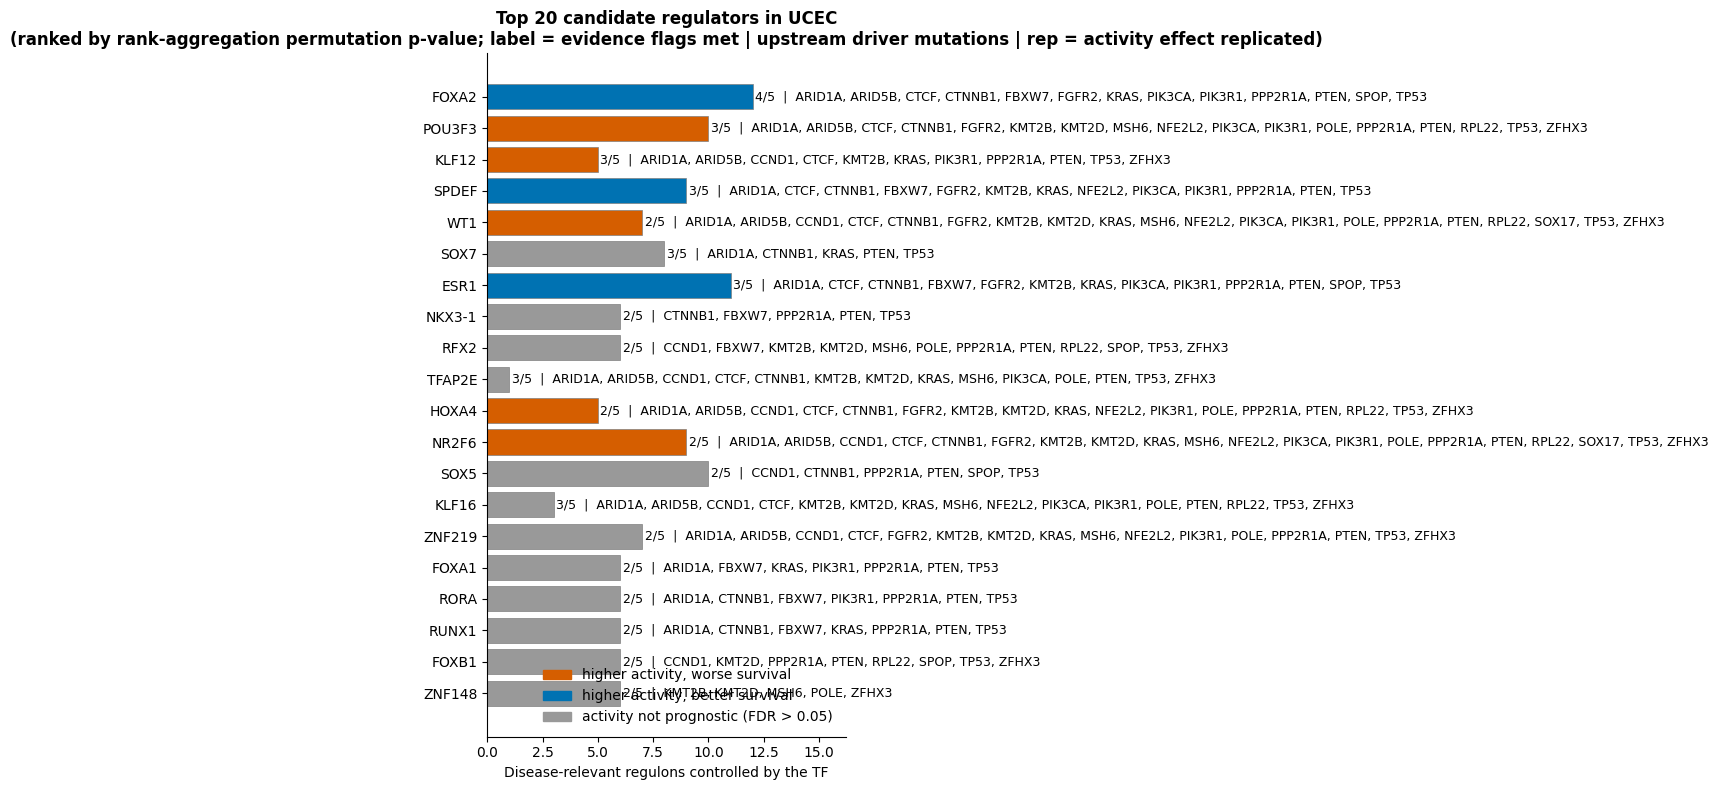

In [11]:
# Top 20 candidate regulators
# Bar length = number of disease-relevant regulons the TF controls
# Colour = direction of the TF's ACTIVITY effect on survival (E4: stratified Cox over TCGA and the independent cohort, FDR <= 0.05);
#          grey = activity not prognostic. (The regulon-based `direction` column is not used: a regulon eigengene's sign follows its
#          genes, not the TF, so a "risk" regulon can belong to a TF that represses it.)
# Order = rank aggregation permutation p-value. Text to the right = evidence flags met, upstream driver mutations,
#         and "rep" when the activity effect is significant (|z| >= 1.96) in both cohorts with the same sign
z_cols = [c for c in tf.columns if c.startswith("act_z_")]
tf["act_replicated"] = (len(z_cols) == 2) & (tf[z_cols].abs() >= 1.96).all(axis=1) & (np.sign(tf[z_cols[0]]) == np.sign(tf[z_cols[-1]]))
tf.to_csv(os.path.join(output_dir, "candidate_regulators.csv"))
print(f"TFs whose activity predicts survival in both cohorts, same direction: {int(tf['act_replicated'].sum())} "
      f"| of these in the top 50: {int(tf[tf['expressed'].fillna(False)].head(50)['act_replicated'].sum())}")

top = tf[tf["expressed"].fillna(False)].head(20).iloc[::-1]
def colour(r):
    if not (r["act_fdr"] <= 0.05):
        return "#999999"
    return "#D55E00" if r["act_z"] > 0 else "#0072B2"

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(top.index, top["n_final"], color=[colour(r) for _, r in top.iterrows()], edgecolor="grey", linewidth=0.5)
for y, (g, r) in enumerate(top.iterrows()):
    label = f"{int(r['evidence_score'])}/5" + (f"  |  {r['upstream_drivers']}" if r["upstream_drivers"] else "") + ("  |  rep" if r["act_replicated"] else "")
    ax.text(r["n_final"] + top["n_final"].max() * 0.01, y, label, va="center", fontsize=9)

ax.set_xlim(0, top["n_final"].max() * 1.35)
ax.set_xlabel("Disease-relevant regulons controlled by the TF")
ax.set_title(f"Top 20 candidate regulators in {CANCER}\n(ranked by rank-aggregation permutation p-value; label = evidence flags met | upstream driver mutations | rep = activity effect replicated)", fontweight="bold")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#D55E00", "#0072B2", "#999999")],
          labels=["higher activity, worse survival", "higher activity, better survival", "activity not prognostic (FDR > 0.05)"],
          loc="lower right", frameon=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "candidate_regulators_top20.png"), dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Candidate shortlist: TFs with replicated, mechanism-linked evidence, split into known biology and under-studied candidates
#   1. replicated:   activity predicts survival in TCGA and the independent cohort, same direction (act_replicated)
#                    (cancers without a cohort with survival: activity FDR <= 0.05 in TCGA instead, marked in the table)
#   2. driver-linked: at least one driver mutation -> TF -> disease-relevant regulon flow (E3_driver_linked)
#   3. tumour-intrinsic: not a known immune / endothelial / stromal lineage TF, and its expression is not strongly tied to the
#      stromal or immune score of the tumour (|Spearman rho| < COMPOSITION_RHO); such TFs mostly report which cells are in the sample
#   4. novelty: Open Targets association with this cancer; "No prior association" or "Weak prior evidence" = under-studied
# The shortlist is a hypothesis list: everything here is association in patient data (no functional evidence)
from scipy.stats import spearmanr

COMPOSITION_RHO = 0.6
LINEAGE_TFS = {
    # myeloid / lymphoid
    "SPI1", "SPIB", "IRF4", "IRF8", "IKZF1", "IKZF2", "IKZF3", "RUNX3", "TBX21", "EOMES", "STAT4", "GFI1", "MAFB", "PAX5",
    "POU2AF1", "BCL11B", "TCF7", "LYL1", "LEF1",
    # endothelial
    "ERG", "FLI1", "SOX7", "SOX17", "SOX18", "TAL1", "MECOM", "ETV2",
    # fibroblast / smooth muscle
    "TWIST1", "TWIST2", "PRRX1", "TCF21", "FOXF1", "MYOCD"}

sl = tf[tf["expressed"].fillna(False)].copy()

# 1. Replication (or TCGA-only activity where there is no independent cohort with survival)
has_cohort = len([c for c in sl.columns if c.startswith("act_z_")]) == 2
sl["evidence_activity"] = sl["act_replicated"] if has_cohort else (sl["act_fdr"] <= 0.05)

# 3. Composition: correlation of the TF's expression with the stromal and immune scores (TCGA, from the purity cell)
sl["rho_stromal"], sl["rho_immune"] = np.nan, np.nan
if purity is not None:
    pts = [p for p in log_tpm.columns if p in purity.index]
    for g in sl.index:
        if g in log_tpm.index:
            x = log_tpm.loc[g, pts].values
            sl.loc[g, "rho_stromal"] = spearmanr(x, purity.loc[pts, "stromal"].values)[0]
            sl.loc[g, "rho_immune"]  = spearmanr(x, purity.loc[pts, "immune"].values)[0]
sl["composition_flag"] = sl.index.isin(LINEAGE_TFS) | (sl[["rho_stromal", "rho_immune"]].abs().max(axis=1) >= COMPOSITION_RHO)

# 4. Novelty
if "OT_status" in sl.columns:
    sl["under_studied"] = sl["OT_status"].isin(["No prior association", "Weak prior evidence"])
else:
    sl["under_studied"] = np.nan
    print("Open Targets annotation missing: novelty not assessed")

passes = sl["evidence_activity"].fillna(False) & sl["E3_driver_linked"] & ~sl["composition_flag"]
shortlist = sl[passes].copy()
shortlist["group"] = np.where(shortlist["under_studied"] == True, "candidate (under-studied)", "known biology")
shortlist = shortlist.sort_values(["group", "rra_p"])

keep_cols = ["group", "rank", "rra_p", "act_z"] + [c for c in shortlist.columns if c.startswith("act_z_")] + \
            ["act_fdr", "upstream_drivers", "n_final", "n_states_master", "median_TPM", "rho_stromal", "rho_immune", "OT_score", "OT_status"]
keep_cols = [c for c in dict.fromkeys(keep_cols) if c in shortlist.columns]
shortlist[keep_cols].to_csv(os.path.join(output_dir, "candidate_shortlist.csv"))

print(f"Expressed TFs: {len(sl)}")
print(f"  1. activity {'replicated in both cohorts' if has_cohort else 'prognostic in TCGA (no cohort with survival)'}: {int(sl['evidence_activity'].fillna(False).sum())}")
print(f"  2. and driver-linked: {int((sl['evidence_activity'].fillna(False) & sl['E3_driver_linked']).sum())}")
print(f"  3. and not a composition TF: {len(shortlist)}  (removed as lineage list: {sorted(set(sl.index[sl['evidence_activity'].fillna(False) & sl['E3_driver_linked'] & sl.index.isin(LINEAGE_TFS)]))})")
print(f"  4. of these under-studied: {int((shortlist['group'] == 'candidate (under-studied)').sum())} | known biology: {int((shortlist['group'] == 'known biology').sum())}")
print("\nSaved candidate_shortlist.csv")
print(shortlist[keep_cols].round(3).to_string())

Expressed TFs: 445
  1. activity prognostic in TCGA (no cohort with survival): 41
  2. and driver-linked: 29
  3. and not a composition TF: 29  (removed as lineage list: [])
  4. of these under-studied: 22 | known biology: 7

Saved candidate_shortlist.csv
                             group   rank  rra_p  act_z  act_z_TCGA  act_fdr                                                                                                                              upstream_drivers  n_final  n_states_master  median_TPM  rho_stromal  rho_immune  OT_score             OT_status
TF                                                                                                                                                                                                                                                                                                                       
FOXA2    candidate (under-studied)    1.0  0.000 -4.812      -4.812    0.000                                        